In [1]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import image
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import time
import os

In [2]:
# path for train, test and valid directory

train_dir = 'D:\\download\\100 bird species\\100-bird-species\\train'
test_dir = 'D:\\download\\100 bird species\\100-bird-species\\test'
valid_dir = 'D:\\download\\100 bird species\\100-bird-species\\valid'

# classes of birds
classes=os.listdir(test_dir)

# making dictionary such that if a number(code) is given between 0 to 184 , i can tell class of bird
# and if class is given , i can tell a number code for corresponding class
label_code = {}
code_label = {}
a = 0
for i in classes:
    label_code.update({i:a})
    code_label.update({a:i})
    a+=1
    

In [3]:
# this will create data set from directory

def create_data(n):
    a = [train_dir,test_dir,valid_dir]
    data = []
    for i in os.listdir(a[n]):
        species_path = os.path.join(a[n],i)
        for j in (os.listdir(species_path)):
            npath = os.path.join(species_path,j)
            img = image.imread(npath)
            data.append([img/255,i])
    return data

In [4]:
# this will make x and y set

from random import shuffle
def making_set(data):
    shuffle(data)
    X_set = []
    Y_set = []
    code = [0]*185
    for i in range(len(data)):
        X_set.append(data[i][0])
        code = [0]*185
        code[label_code[data[i][1]]] = 1
        Y_set.append((code))
    return [(np.asarray(X_set)),(np.asarray(Y_set))]

In [5]:
# using generator so that model use less ram of laptop

generator = ImageDataGenerator(horizontal_flip = True, vertical_flip = True,rescale = 1/255,
                               width_shift_range = 0.1,zoom_range=0.1,height_shift_range = 0.1)

# Training data
train_data = generator.flow_from_directory(train_dir, target_size=(224,224),
                                                 batch_size=64, 
                                                 class_mode="categorical")

# Testing data
test_data = generator.flow_from_directory(test_dir, target_size=(224,224),
                                                 batch_size=64,shuffle=False,
                                               class_mode="categorical")

# Validation data
valid_data = generator.flow_from_directory(valid_dir, target_size=(224,224),
                                                 batch_size=64,shuffle=False,
                                                  class_mode="categorical")

Found 25171 images belonging to 185 classes.
Found 925 images belonging to 185 classes.
Found 925 images belonging to 185 classes.


In [6]:
# function used if we want to run model training for more required epoch to reach optimum accuracy
# this will ask number of epoch we want to run more
# if we dnt want to run more, press n and training will be stopped

def run_more():
    
    while True :
        x = input('For more training, Input number of epoch (+ve integer) for more training OR press " N " to stop\n')
        if x.upper() == 'N':
            print('\033[1m','-----------End Of Training-----------','\033[0m \n')
            
            return [False,0]
        
        else :
            try:
                # this will help if input is not integar, function will ask again if input is not integar
                if int(x) >= 0 :
                    return [True,int(x)]
                else:
                    print('Please provide positive integar\n')
                
            except ValueError:
                print('\033[1m','incorrect input\n','\033[0m \n')

In [7]:
# loading mobilenet model

mobile_net = tf.keras.applications.mobilenet.MobileNet( include_top=False,
                                                           input_shape=(224,224,3),
                                                            weights='imagenet',pooling='max',
                                                           dropout=.4)
Input = mobile_net.input

x = tf.keras.layers.BatchNormalization(axis=-1, momentum=0.99, epsilon=0.001 )(mobile_net.layers[-1].output)

output = layers.Dense (len(label_code), activation='softmax')(x)

model3 = Model(Input, output)    

for layer in model3.layers:
    layer.trainable=True

model3.summary()

Model: "model"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
input_1 (InputLayer)         [(None, 224, 224, 3)]     0         
_________________________________________________________________
conv1_pad (ZeroPadding2D)    (None, 225, 225, 3)       0         
_________________________________________________________________
conv1 (Conv2D)               (None, 112, 112, 32)      864       
_________________________________________________________________
conv1_bn (BatchNormalization (None, 112, 112, 32)      128       
_________________________________________________________________
conv1_relu (ReLU)            (None, 112, 112, 32)      0         
_________________________________________________________________
conv_dw_1 (DepthwiseConv2D)  (None, 112, 112, 32)      288       
_________________________________________________________________
conv_dw_1_bn (BatchNormaliza (None, 112, 112, 32)      128   

In [8]:
model3.compile(tf.keras.optimizers.Adamax(lr=0.006), loss='categorical_crossentropy', metrics=['accuracy'])

In [ ]:

# list to store training, validation loss and training , validation accuracy for each epoch
# this needs if we want to run for more epoch
# beacause if we run more, history will be updated for that run only and goes on changing
# so we need to store for all epoch till we train

train_loss = []
valid_loss = []
train_accuracy = []
valid_accuracy = []
start_epoch = 0


reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.2,
                              patience=1, min_lr=0.001)


start = time.time()
while True :
    if start_epoch == 0 :
        history = model3.fit(train_data,validation_data = valid_data,epochs = 3,
                             callbacks=[reduce_lr])
            
    else :
        history = model3.fit(train_data, validation_data = valid_data, epochs = epoch,
                            initial_epoch = start_epoch, 
                             callbacks=[reduce_lr])
    
    for i in (history.history['loss']):
        train_loss.append(i)
    
    for i in (history.history['accuracy']):
        train_accuracy.append(i)
        
    for i in (history.history['val_loss']):
        valid_loss.append(i)
        
    for i in (history.history['val_accuracy']):
        valid_accuracy.append(i)
        
    end_epoch = history.epoch[-1] # storing last epoch number
    
    Run_More = run_more() # calling runmore function if we want to run for more epoch
    epoch = end_epoch +1 + Run_More[1]
    if Run_More[0] == False :
        break
    start_epoch = end_epoch +1

end = time.time()
hours = int(np.floor((end-start)/3600))
minute = int(np.floor(((end-start)/3600 - hours)*60))
sec = int(np.floor((((end-start)/3600 - hours)*60-minute)*60))

print(f'\n\nTotal training time is : {hours} hours, {minute} minutes, {sec} seconds')

  ...
    to  
  ['...']
  ...
    to  
  ['...']
Train for 394 steps, validate for 15 steps
Epoch 1/3
394/394 [==============================] - 793s 2s/step - loss: 3.0573 - accuracy: 0.3260 - val_loss: 2.7088 - val_accuracy: 0.3330
Epoch 2/3
394/394 [==============================] - 459s 1s/step - loss: 1.1900 - accuracy: 0.6914 - val_loss: 1.7027 - val_accuracy: 0.5676
Epoch 3/3
394/394 [==============================] - 341s 866ms/step - loss: 0.8056 - accuracy: 0.7846 - val_loss: 1.5288 - val_accuracy: 0.5978
For more training, Input number of epoch (+ve integer) for more training OR press " N " to stop
17
  ...
    to  
  ['...']
  ...
    to  
  ['...']
Train for 394 steps, validate for 15 steps
Epoch 4/20
394/394 [==============================] - 317s 804ms/step - loss: 0.6419 - accuracy: 0.8255 - val_loss: 1.3342 - val_accuracy: 0.6670
Epoch 5/20
394/394 [==============================] - 327s 829ms/step - loss: 0.5327 - accuracy: 0.8505 - val_loss: 1.0872 - val_accuracy: 0

In [18]:
np.save('D:\\download\\100 bird species\\history_bird_mobilenet_wg_model3_copy3.npy',history.history)

In [14]:
result = model3.evaluate(test_data)
print(f'Accuracy on test set is : {result[1]*100}%')

  ...
    to  
  ['...']
15/15 [==============================] - 12s 772ms/step - loss: 0.0564 - accuracy: 0.9816
Accuracy on test set is : 98.16216230392456%


In [15]:
# original Test data from directory without generator
test_data2 = create_data(1)

In [16]:
X_test,Y_test = making_set(test_data2)

In [17]:
result = model3.evaluate(X_test,Y_test)

print(f'Accuracy on test set is : {result[1]*100}%')

925/925 [==============================] - 7s 8ms/sample - loss: 0.0567 - accuracy: 0.9827
Accuracy on test set is : 98.27027320861816%


In [19]:

model3.save('D:\\download\\100 bird species\\bird_mobilenet_wg_model3_copy3.h5')

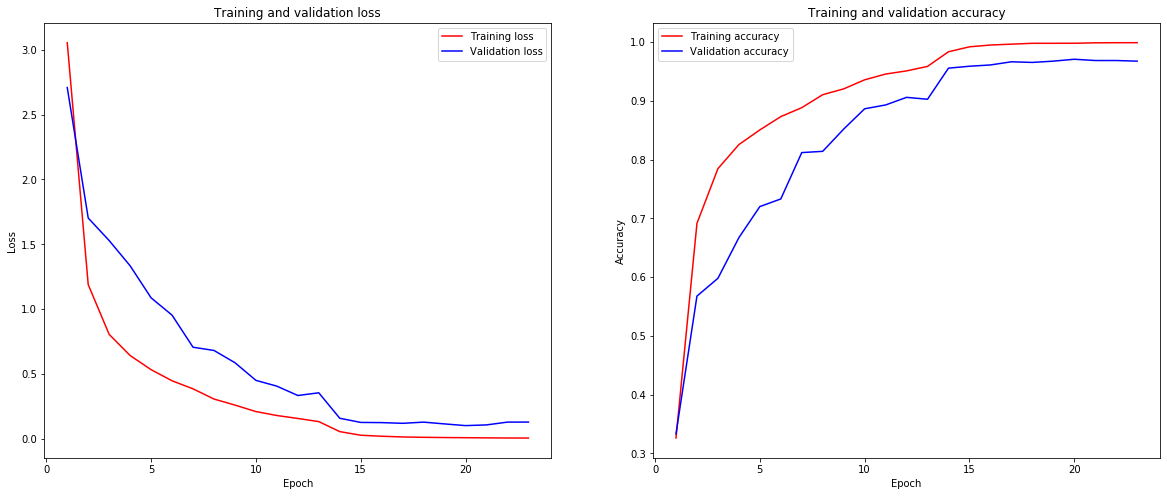

In [20]:
epoch_count = [i for i in range(1,(epoch)+1)]
plt.figure(figsize = (20,8))
plt.subplot(1,2,1)
plt.plot(epoch_count,train_loss,color = 'r',label = 'Training loss')
plt.plot(epoch_count,valid_loss,color = 'b',label = 'Validation loss')
plt.title('Training and validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(epoch_count,train_accuracy,color = 'r',label = 'Training accuracy')
plt.plot(epoch_count,valid_accuracy,color = 'b',label = 'Validation accuracy')
plt.title('Training and validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('D:\\download\\100 bird species\\bird_mobilenet_wg_model3_copy3_plot.png',dpi=200)
plt.show()

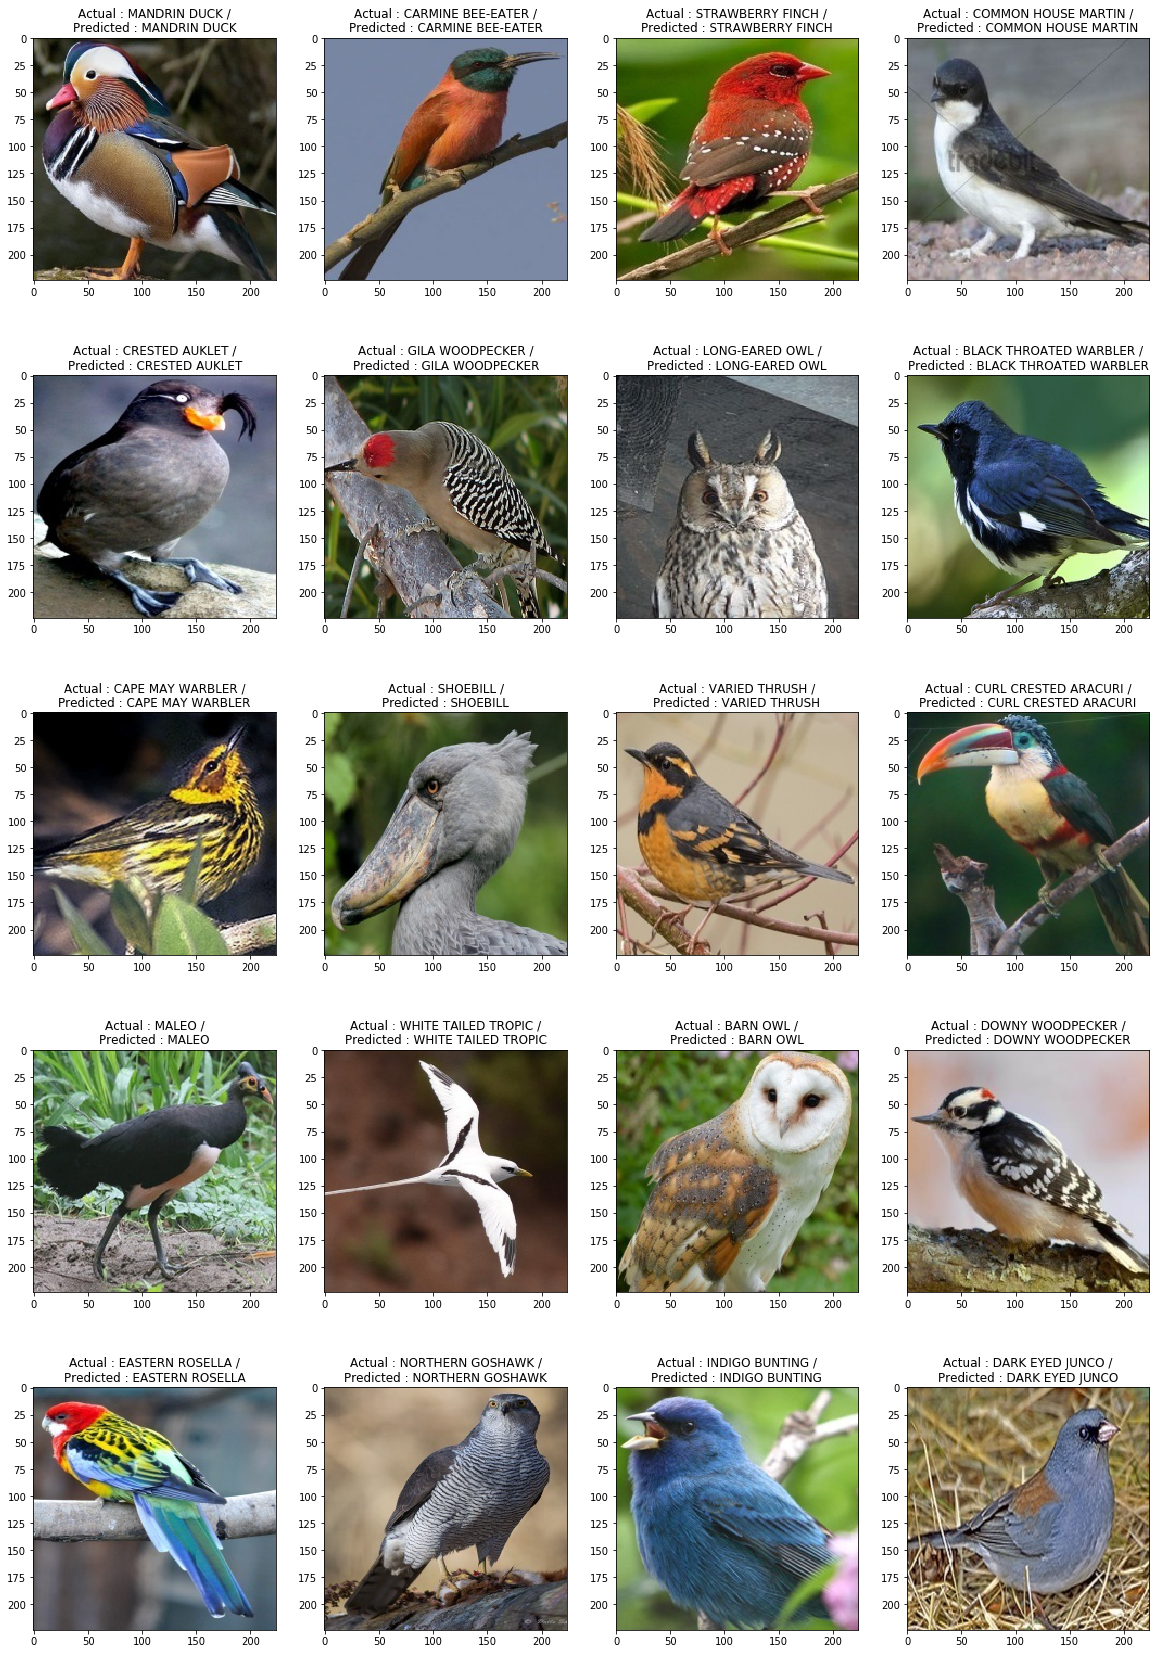

In [21]:
from matplotlib import image
import random
plt.figure(figsize=(20,30))
for i in range(20):
    species = os.listdir(test_dir)[random.randint(0,184)]
    path = os.path.join(test_dir,species)
    img_label = os.listdir(path)[random.randint(0,4)]
    path = os.path.join(path,img_label)
    img = np.array(image.imread(path))/255
    pred = np.argmax(model3.predict(img.reshape(1,224,224,3)))
    pred_species = code_label[pred]
    plt.subplot(5,4,i+1)
    plt.imshow(img)
    plt.title(f'Actual : {species} /\nPredicted : {pred_species}')

plt.show()


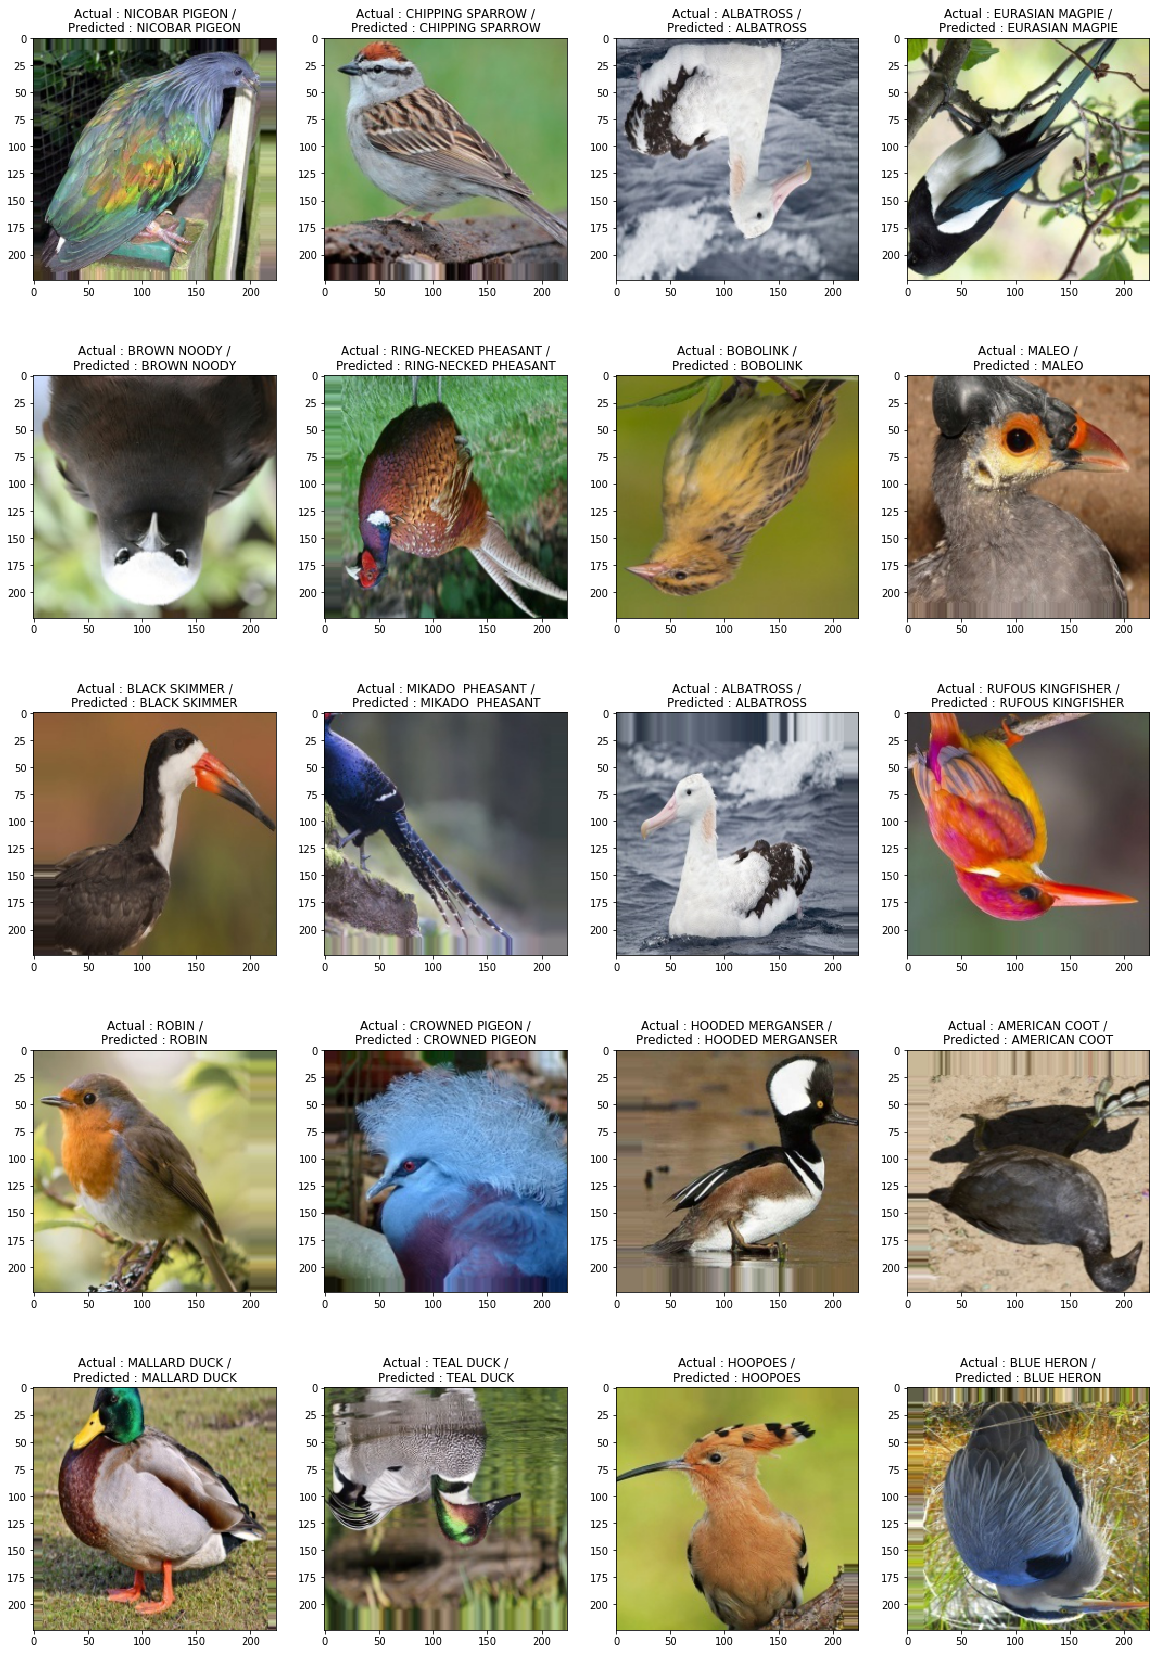

In [22]:

# plotting some prdiction from test genrator

from matplotlib import image
import random
plt.figure(figsize=(20,30))
for i in range(20):
    a = random.randint(0,13)
    b = random.randint(0,63)
    species = classes[(test_data[a][1][b]).argmax()]
    img = test_data[a][0][b]
    pred = np.argmax(model3.predict(img.reshape(1,224,224,3)))
    pred_species = classes[pred]
    plt.subplot(5,4,i+1)
    plt.imshow((img*255).astype(np.uint8))
    plt.title(f'Actual : {species} /\nPredicted : {pred_species}')

plt.show()

In [23]:
from sklearn.metrics import classification_report
import pandas as pd

predictions = model3.predict(test_data)
predicted_classes = np.argmax(predictions, axis=-1)
true_classes = test_data.classes
class_labels = list(test_data.class_indices.keys())

report = classification_report(true_classes, predicted_classes, 
                               target_names = class_labels,
                               digits = 2,output_dict = True)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv('D:\\download\\100 bird species\\mobilenet_wg_model3_Copy3.csv')
report_df

,precision,recall,f1-score,support
ALBATROSS,0.800000,0.800000,0.800000,5.000000
ALEXANDRINE PARAKEET,1.000000,1.000000,1.000000,5.000000
AMERICAN AVOCET,1.000000,1.000000,1.000000,5.000000
AMERICAN BITTERN,1.000000,1.000000,1.000000,5.000000
AMERICAN COOT,1.000000,1.000000,1.000000,5.000000
...,...,...,...,...
WOOD DUCK,1.000000,1.000000,1.000000,5.000000
YELLOW HEADED BLACKBIRD,1.000000,1.000000,1.000000,5.000000
accuracy,0.983784,0.983784,0.983784,0.983784
macro avg,0.986126,0.983784,0.983492,925.000000


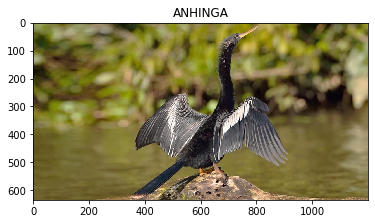

In [24]:
# Load the image

import matplotlib as m
import cv2
from PIL import Image
import requests
from io import BytesIO

# some bird url from google to check model preiction
# Razorbill : 'https://encrypted-tbn0.gstatic.com/images?q=tbn%3AANd9GcT-BWaNju76a-2FDIcQtO1dvFzRy30K0oaHyDYmVJlJRop1kO7G&usqp=CAU'
# Elliots Pheasant : https://www.birdforum.net/opus/images/thumb/1/1e/IMG_1237g.jpg/550px-IMG_1237g.jpg

#response = requests.get('https://encrypted-tbn0.gstatic.com/images?q=tbn%3AANd9GcT-BWaNju76a-2FDIcQtO1dvFzRy30K0oaHyDYmVJlJRop1kO7G&usqp=CAU')


#img = np.asarray(Image.open(BytesIO(response.content)))

# below one is downloaded in hard-drive and then checked

img = m.image.imread('test1.jpg')

plt.imshow(img)

# We resize the image to the input width and height of the first layer of the network.
resized_image = cv2.resize(img, (224, 224))
title = code_label[np.argmax(model3.predict((resized_image.reshape(1,224,224,3))/255))]
plt.title(title)
plt.show()



In [25]:
tf.keras.utils.plot_model(
    model3, to_file='D:\\download\\100 bird species\\mobilenet_wg_model3-Copy3_layout_plot.png', show_shapes=True, show_layer_names=True,
    rankdir='TB', expand_nested=False, dpi=500
)